# UniRemington - Cali<br>Facultad de Ingeniería - Línea de Énfasis III: Análisis de Datos<br>(ↄ) Diego Fernando Marin, 2026-2

## Datos del Estudiante

**Código**: <br>
**Nombre**:Andres Esteban vasquez peña <br>
**Correo**:andres.vasquez.2360@miremington.edu.co

# Taller #1 - Encuesta TV

## 0. Introducción

### ¿Qué vas a hacer en este taller?

Vas a realizar un **análisis exploratorio de datos (EDA)** sobre una encuesta de hábitos de televisión: quién ve qué, cuántas horas y cuánto paga por sus suscripciones. Lo harás con las dos librerías base del ecosistema de ciencia de datos en Python: **Pandas** (manipulación de tablas) y **Matplotlib** (gráficos).

### Alcance

Al terminar serás capaz de:

1. Inspeccionar un conjunto de datos nuevo (tamaño, tipos, valores faltantes).
2. Filtrar, contar, agrupar y ordenar con operaciones *vectorizadas* (sin recorrer filas con `for`).
3. Elegir y construir el gráfico adecuado para cada tipo de pregunta.
4. Contrastar hipótesis simples (¿hay diferencia entre hombres y mujeres?) y detectar *outliers*.
5. **Comunicar con honestidad** lo que los datos permiten (y no permiten) concluir.

## 1. Contexto del problema

Imagina que trabajas para un canal regional o una plataforma de *streaming* que quiere entender mejor a su audiencia. Se aplicó una encuesta corta a **68 personas** y la gerencia quiere respuestas a preguntas como:

- ¿Quiénes son los encuestados (edad, género)?
- ¿Qué canales son los más queridos y **quién los prefiere**? Esto orienta qué contenidos comprar o promocionar.
- ¿Ven más televisión los jóvenes o los adultos? Esto orienta **en qué franja** y con qué formato publicar.
- ¿Cuánto pagan por sus suscripciones y **qué tipo de persona paga más**? Esto orienta la política de precios.

**¿Por qué EDA y no directamente un modelo?** Porque antes de predecir hay que *entender*: un análisis exploratorio revela errores en los datos, patrones y preguntas nuevas, y evita construir modelos sobre supuestos falsos.

### Diccionario de datos

| Variable | Descripción | Tipo esperado |
|---|---|---|
| `nombre` | Nombre del encuestado | texto |
| `edad` | Edad en años | entero |
| `genero` | `M` (masculino) o `F` (femenino) | categórica |
| `canal_fav1`, `canal_fav2`, `canal_fav3` | Primer, segundo y tercer canal favorito | texto |
| `horas` | Horas de consumo de TV (horas x día) | entero |
| `costo_mes` | Costo mensual de suscripciones (pesos colombianos) | entero |

## 2. Preparación del entorno

Esta celda ya está completa: es el **ejemplo resuelto** que te muestra el estilo de las siguientes. Ejecútala y lee cada línea.

In [1]:
# 1) Descarga el archivo y lo guarda como encuesta_tv.csv (en Colab/Jupyter, el "!" ejecuta un comando de consola)
!wget --no-verbose -O encuesta_tv.csv https://paste.c-net.org/WimpsPaolo

2026-10-28 18:39:12 URL:https://paste.c-net.org/WimpsPaolo [3134/3134] -> "encuesta_tv.csv" [1]


In [2]:
# 2) Importamos las librerías con sus alias convencionales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# 3) Cargamos el CSV. OJO: el separador NO es coma, es una barra vertical "|"
df = pd.read_csv('encuesta_tv.csv', sep='|')

> **Teoría — separadores.** `read_csv` asume por defecto que las columnas están separadas por coma. Si el archivo usa otro carácter y no lo indicas con `sep=`, obtendrás **una sola columna** con todo pegado. Si te ocurre, ese es el primer sospechoso.

> **Alternativa sin `wget`:** `pd.read_csv('https://paste.c-net.org/WimpsPaolo', sep='|')` lee directamente desde la URL.

## Parte 1 — Primer contacto con los datos (Pasos 1–4)

> **Teoría.** Antes de calcular nada, un analista responde tres preguntas: *¿cuánto hay?* (dimensiones), *¿de qué tipo es cada columna?* (tipos y nulos) y *¿cómo se ve?* (muestras del inicio **y** del final; el final puede revelar registros agregados más tarde con otro formato).


### Paso 1. ¿Cuántos registros (filas) y variables (columnas) hay?

**Lógica:** `shape` devuelve una *tupla* `(filas, columnas)`.

In [ ]:
# Obtén las dimensiones del DataFrame.
# Pista: shape es un ATRIBUTO (no lleva paréntesis).
df

,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
0,orlando,35,M,RCN,Telepacifico,HBO+,4,25000
1,jennifer,18,F,Caracol,RCN,Netflix,8,18000
2,julián,33,M,CNN,Star+,Disney+,5,23000
3,luisa,25,F,RCN,Caracol,Cinemax,6,15000
4,marcelo,16,M,Boomerang,Cartoon Network,Disney+,9,20000
...,...,...,...,...,...,...,...,...
63,maria,26,F,Netflix,HBO+,Disney+,5,21000
64,andres felipe,36,M,RCN,Caracol,Telepacifico,7,20000
65,juliana,24,F,ESPN,ESPN2,Fox Sports,4,22000
66,pablo,37,M,HBO+,Netflix,Amazon Prime,6,23000


### Paso 2. ¿Cuáles son las variables, sus nombres y tipos?

**Lógica:** `info()` resume nombre, **cantidad de valores no nulos** y tipo (`dtype`) de cada columna. Compara el número de no nulos con el total de filas: ahí se descubren los datos faltantes.

In [ ]:
# Muestra el resumen estructural del DataFrame.
# Pista: info() es un MÉTODO (sí lleva paréntesis) e imprime directamente.
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68 entries, 0 to 67
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   nombre      68 non-null     object
 1   edad        68 non-null     int64 
 2   genero      68 non-null     object
 3   canal_fav1  68 non-null     object
 4   canal_fav2  68 non-null     object
 5   canal_fav3  67 non-null     object
 6   horas       68 non-null     int64 
 7   costo_mes   68 non-null     int64 
dtypes: int64(3), object(5)
memory usage: 4.4+ KB


### Paso 3. Muestra las primeras 10 filas de los datos.

In [ ]:
# Muestra las 10 primeras filas.
# Pista: head(n) recibe el número de filas.
df.head(11)

,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
0,orlando,35,M,RCN,Telepacifico,HBO+,4,25000
1,jennifer,18,F,Caracol,RCN,Netflix,8,18000
2,julián,33,M,CNN,Star+,Disney+,5,23000
3,luisa,25,F,RCN,Caracol,Cinemax,6,15000
4,marcelo,16,M,Boomerang,Cartoon Network,Disney+,9,20000
5,guillermo,41,M,ESPN,ESPN2,Fox Sports,10,25000
6,stephany,11,F,Disney+,Star+,Amazon Prime,6,19000
7,mariana,32,F,Star+,HBO+,Paramount+,4,21000
8,juan,28,M,Fox,HBO+,Netflix,7,22000
9,andrea,20,F,Caracol,RCN,Netflix,5,19000


### Paso 4. Muestra las últimas 10 filas de los datos.

In [ ]:
# Muestra las 10 últimas filas.
# Pista: es el método "hermano" de head().
df.tail(10)

,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
58,paola,25,F,ESPN,ESPN2,Fox Sports,4,21000
59,juanita maria,34,F,HBO+,Netflix,Amazon Prime,6,23000
60,carlos andres,32,M,CNN,BBC,Discovery,5,24000
61,lina,23,F,HBO+,Netflix,Amazon Prime,7,20000
62,felipe andres,35,M,ESPN,ESPN2,Fox Sports,6,22000
63,maria,26,F,Netflix,HBO+,Disney+,5,21000
64,andres felipe,36,M,RCN,Caracol,Telepacifico,7,20000
65,juliana,24,F,ESPN,ESPN2,Fox Sports,4,22000
66,pablo,37,M,HBO+,Netflix,Amazon Prime,6,23000
67,juana,29,F,CNN,BBC,Discovery,5,21000


### Evaluación — Parte 1

- **E1.1 (conceptual).** En la salida de `info()` una columna muestra menos valores no nulos que las demás. ¿Cuál es y qué significa?

un usuario no tiene un tercer canal favorito

- **E1.2 (conceptual).** ¿Por qué `df.shape` se escribe sin paréntesis y `df.info()` con ellos?

shape es un atributo y info es un metodo

- **E1.3 (código).** Obtén de una sola vez las estadísticas descriptivas (conteo, media, desviación, mínimo, cuartiles, máximo) de las columnas numéricas.

In [ ]:
# Reto E1.3 — Pista: existe un método cuyo nombre en inglés significa "describir".
df.describe()

,edad,horas,costo_mes
count,68.000000,68.000000,68.000000
mean,29.882353,6.102941,21470.588235
std,11.033909,1.497657,2215.754905
min,11.000000,4.000000,15000.000000
25%,21.750000,5.000000,20000.000000
50%,29.000000,6.000000,22000.000000
75%,37.000000,7.000000,23000.000000
max,53.000000,10.000000,27000.000000


## Parte 2 — Valores únicos, estadísticas y conteos (Pasos 5–8)

> **Teoría.** Tres herramientas que usarás todo el curso:
> - `Serie.unique()` → los valores distintos (como arreglo).
> - `Serie.nunique()` → **cuántos** valores distintos hay (ignora `NaN`).
> - `Serie.value_counts()` → cuántas veces aparece cada valor, ordenado de mayor a menor.


### Paso 5. ¿Cuáles son los nombres únicos de las personas encuestadas?

In [ ]:
# Obtén los nombres distintos de la columna 'nombre'.
# Pista: selecciona la columna con df['nombre'] y aplica el método de valores únicos.
df['nombre'].unique()

array(['orlando', 'jennifer', 'julián', 'luisa', 'marcelo', 'guillermo',
       'stephany', 'mariana', 'juan', 'andrea', 'carlos', 'valentina',
       'diego', 'camila', 'felipe', 'ana', 'oscar', 'natalia', 'daniel',
       'sara', 'luis', 'catalina', 'pedro', 'alejandra', 'rodrigo',
       'laura', 'manuel', 'andres', 'patricia', 'ana maria', 'jose',
       'andres felipe', 'santiago', 'carolina', 'diana', 'andres david',
       'sergio', 'margarita', 'juanita', 'carlos alberto',
       'andrea carolina', 'carlos enrique', 'marcela', 'lucas',
       'patricia andrea', 'pedro jose', 'luis alberto', 'andrea maria',
       'jose luis', 'carla', 'miguel', 'luz', 'juan pablo', 'camilo',
       'andrea patricia', 'roberto', 'claudia', 'alejandro', 'paola',
       'juanita maria', 'carlos andres', 'lina', 'felipe andres', 'maria',
       'juliana', 'pablo', 'juana'], dtype=object)

### Paso 6. ¿Cuántos canales únicos hay y cuáles son?

**Lógica:** los canales están repartidos en **tres columnas**. Para contarlos como un solo conjunto primero hay que *apilar* las tres columnas en una sola Serie con `pd.concat([...])`.


In [4]:
# 1. Apila canal_fav1, canal_fav2 y canal_fav3 en una sola Serie (guárdala en la variable 'canales').
# 2. Muestra los canales distintos con unique().
# 3. Cuenta cuántos hay con nunique() y compara con len(canales.unique()).
canal = pd.concat([df['canal_fav1'],df['canal_fav2'],df['canal_fav3']])
canal.unique()
canal.nunique()
len(canal.unique())

29

> **Advertencia — `NaN` es un valor.** `unique()` **incluye** el valor faltante (`NaN`) como si fuera un canal; `nunique()` lo ignora. Si cuentas con `len(unique())` obtendrás un canal "fantasma".

### Paso 7. ¿Cuál es el promedio de edad?

In [5]:
# Calcula la edad promedio.
# Pista: df['edad'] + método de la media.
# Exploración extra: prueba .min(), .max(), .median(), .sum(), .count()
df['edad'].mean()

np.float64(29.88235294117647)

> Los métodos de resumen de una Serie incluyen `.min()`, `.max()`, `.median()`, `.sum()`, `.count()` y `.value_counts()`. (En el comentario del cuaderno original aparece escrito `values_count`, que **no existe**: el nombre correcto es `value_counts`.)

### Paso 8. ¿Cuántos encuestados son hombres y cuántas mujeres?

Resuelve el conteo de DOS formas.

In [6]:
# Forma A: value_counts() sobre la columna 'genero'.
df.genero.value_counts()


,count
genero,
M,35
F,33


In [7]:
# Forma B: df.groupby('genero') seguido de .size()
df.groupby('genero').size()

,0
genero,
F,33
M,35


### Evaluación — Parte 2

- **E2.1 (conceptual).** En el Paso 6, ¿por qué `len(canales.unique())` y `canales.nunique()` dan resultados distintos? ¿Cuál es la cifra correcta de canales?

1. Porque unique() incluye los valores nulos (NaN) en su arreglo de conteo, mientras que nunique() los ignora automáticamente.
2. es 29 que es la que reporta nunique(), dado que el valor vacío (NaN) no representa un canal de televisión.

- **E2.2 (código).** `nombre` tiene menos valores únicos que filas. Encuentra **todas** las filas cuyo nombre está repetido. ¿Son la misma persona?

In [8]:
# Pista E2.2 -> duplicated(keep=False) marca TODAS las filas repetidas, no solo la segunda aparición.
filas_repetidas = df[df.duplicated(subset=['nombre'], keep=False)]
display(filas_repetidas)

,nombre,edad,genero,canal_fav1,canal_fav2,canal_fav3,horas,costo_mes
31,andres felipe,15,M,Discovery,NatGeo,History,9,20000
64,andres felipe,36,M,RCN,Caracol,Telepacifico,7,20000


- **E2.3 (código).** Calcula el **porcentaje** de hombres y de mujeres (no la cantidad).

In [14]:
# Pista E2.3 -> value_counts() tiene un parámetro que devuelve proporciones (multiplica por 100).
porcentajes = df['genero'].value_counts(normalize=True) * 100
print(porcentajes)

genero
M    51.470588
F    48.529412
Name: proportion, dtype: float64


- **E2.4 (código + conceptual).** Calcula la **mediana** de edad y compárala con la media. ¿Qué te dice la diferencia?

In [13]:
# Pista E2.4 -> .median()
mediana_edad = df['edad'].median()
print("La mediana de edad es:", mediana_edad)

La mediana de edad es: 29.0


## Parte 3 — Filtros y rankings de frecuencia (Pasos 9–11)


> **Teoría — filtrado booleano.** Una condición sobre una columna (`df['edad'] >= 18`) produce una Serie de `True/False`, llamada **máscara**. Al pasarla a `df[...]` quedan solo las filas `True`. Se combinan con `&` (y), `|` (o) y `~` (no), **cada condición entre paréntesis**.

### Paso 9. Muestra los nombres de los hombres mayores de edad

In [15]:
# 1. Crea la máscara 'filtro' combinando (genero == 'M') y (edad >= 18) con &.
filtro = (df['genero'] == 'M') & (df['edad'] >= 18)

In [16]:
# 2. Aplica la máscara a df y muestra solo la columna 'nombre'.
nombres_hombres_mayores = df.loc[filtro, 'nombre']
display(nombres_hombres_mayores)

,nombre
0,orlando
2,julián
5,guillermo
8,juan
10,carlos
12,diego
14,felipe
16,oscar
18,daniel
20,luis


> **Antipatrón — no recorras filas con `for`.** El cuaderno original muestra una versión con `df.iterrows()` y la marca como lo que **NO** se debe hacer: obliga a Python a procesar fila por fila, mientras que la máscara booleana opera sobre toda la columna en código compilado. Con 68 filas no notarás la diferencia; con 10 millones, sí.

In [17]:
# Esto es lo que NO se debe hacer, no es optimo! obliga a usar filas:
for index, datos in df[['nombre', 'genero', 'edad']].iterrows():
    if datos.genero == 'M' and datos.edad >= 18:
        print(datos.nombre)

orlando
julián
guillermo
juan
carlos
diego
felipe
oscar
daniel
luis
pedro
rodrigo
jose
sergio
carlos alberto
carlos enrique
pedro jose
luis alberto
jose luis
miguel
juan pablo
camilo
roberto
alejandro
carlos andres
felipe andres
andres felipe
pablo


### Paso 10. ¿Cuáles son los 3 canales favoritos más comunes?

In [18]:
# 1. Apila las tres columnas de canales (como en el Paso 6).
canales = pd.concat([df['canal_fav1'], df['canal_fav2'], df['canal_fav3']])

In [19]:
# 2. Cuenta la frecuencia de cada canal con value_counts().
frecuencias_canales = canales.value_counts()

In [20]:
# 3. Quédate con los 3 primeros con head(3).
top_3_canales = frecuencias_canales.head(3)
display(top_3_canales)

,count
HBO+,25
Netflix,21
RCN,15


### Paso 11. ¿Cuál es el canal favorito (`canal_fav1`) más popular entre hombres y entre mujeres?

In [21]:
# Agrupa por 'genero', toma la columna 'canal_fav1' y cuenta con value_counts().
preferencias_genero = df.groupby('genero')['canal_fav1'].value_counts()
display(preferencias_genero)

genero  canal_fav1     
F       HBO+                9
        Caracol             5
        CNN                 4
        Netflix             3
        RCN                 3
        ESPN                2
        Teleantioquia       2
        Disney              1
        Disney+             1
        Star+               1
        Telepacifico        1
        Warner              1
M       ESPN               12
        HBO+                5
        Cartoon Network     4
        CNN                 3
        RCN                 3
        Discovery           2
        Fox                 2
        Boomerang           1
        Caracol             1
        Netflix             1
        Warner              1
Name: count, dtype: int64

### Evaluación — Parte 3

- **E3.1 (conceptual).** ¿Por qué en el Paso 9 se escribe `&` y no `and`, y por qué cada condición va entre paréntesis?

1. Porque en Pandas necesitamos evaluar condiciones elemento a elemento a lo largo de toda la columna, lo cual hace el operador `&`. El operador `and` de Python solo sirve para evaluar un único valor de verdad lógico.
2. garantizan que primero se calculen las condiciones individuales antes de unirlas.

- **E3.2 (código).** ¿Cuántas **mujeres menores de edad** hay y cómo se llaman?


In [22]:
# Filtramos por género femenino y edad menor a 18 años
filtro_mujeres_menores = (df['genero'] == 'F') & (df['edad'] < 18)
mujeres_menores = df[filtro_mujeres_menores]
display(mujeres_menores[['nombre', 'edad']])

,nombre,edad
6,stephany,11
29,ana maria,13
38,juanita,16


- **E3.3 (código + conceptual).** Muestra el **top 5** de canales del Paso 10. ¿Qué observas en el tercer puesto? ¿Qué problema crea `head(3)`?


In [47]:
# Mostramos el top 5 de canales favoritos en total
top_5_canales = frecuencias_canales.head(5)
display(top_5_canales)

,count
HBO+,25
Netflix,21
RCN,15
ESPN,15
Caracol,14


Al ver el Top 5, observamos que en el tercer puesto hay un doble empate (RCN y ESPN todos 15 menciones). El problema de usar `head(3)` es que deja por fuera a canales que son igual de populares.

- **E3.4 (código).** El Paso 11 solo mira `canal_fav1`. Repite el análisis considerando **los tres** canales favoritos. *Pista:* `df.melt(id_vars='genero', value_vars=[...], value_name='canal')` convierte tres columnas en una sola columna larga. ¿Cambia la conclusión?

In [24]:
# Convertimos las columnas en una estructura larga
df_largo = df.melt(id_vars='genero', value_vars=['canal_fav1', 'canal_fav2', 'canal_fav3'], value_name='canal')
# Agrupamos por género y contamos la frecuencia de cada canal
preferencias_completas = df_largo.groupby('genero')['canal'].value_counts()
display(preferencias_completas)

genero  canal          
F       HBO+               16
        Netflix            14
        Caracol            11
        RCN                11
        Amazon Prime        9
        BBC                 4
        CNN                 4
        Discovery           4
        Disney+             4
        Teleantioquia       4
        Star+               3
        ESPN                2
        ESPN2               2
        Fox Sports          2
        Telepacifico        2
        Cartoon Network     1
        Cinemax             1
        Disney              1
        Nickelodeon         1
        Paramount+          1
        TNT                 1
        Warner              1
M       ESPN               13
        Fox Sports         12
        HBO+                9
        ESPN2               7
        Netflix             7
        Disney+             6
        Amazon Prime        5
        Boomerang           5
        Cartoon Network     5
        GolTV               5
        Discovery           4
        RCN                 4
        CNN                 3
        Caracol             3
        Telepacifico        3
        BBC                 2
        Fox                 2
        History             2
        NatGeo              2
        Disney              1
        Sony                1
        Star+               1
        Teleantioquia       1
        Warner              1
Name: count, dtype: int64

## Parte 4 — Relaciones entre variables y extremos (Pasos 12–14)

> **Teoría — correlación de Pearson.** `Serie_a.corr(Serie_b)` mide la **relación lineal** entre dos variables numéricas, entre −1 y +1:
> - cercana a **+1**: cuando una sube, la otra tiende a subir;
> - cercana a **−1**: cuando una sube, la otra tiende a bajar;
> - cercana a **0**: *no hay relación lineal* (¡pero puede haber otra forma de relación!).
>
> **Correlación no implica causalidad.**


### Paso 12. ¿Hay relación entre la edad y las horas de consumo de TV?

In [25]:
# Calcula el coeficiente de correlación entre 'edad' y 'horas'.
correlacion = df['edad'].corr(df['horas'])
print("Coeficiente de correlación entre edad y horas de TV:", correlacion)

Coeficiente de correlación entre edad y horas de TV: -0.027255358787632557


### Paso 13. ¿Cuál es el costo promedio mensual de suscripciones?

In [26]:
# Calcula el promedio de la columna 'costo_mes'.
costo_promedio = df['costo_mes'].mean()
print("El costo promedio mensual de suscripción es:", costo_promedio)

El costo promedio mensual de suscripción es: 21470.58823529412


### Paso 14. ¿Cuál es el encuestado más joven y cuál el de mayor edad?

**Lógica:** no basta con el valor mínimo; queremos **quién** es. `idxmin()` / `idxmax()` devuelven la *etiqueta de la fila* donde ocurre el mínimo/máximo, y con `.loc[...]` recuperas esa fila completa.


In [27]:
# Encuentra la fila del más joven y la fila del mayor usando idxmin() e idxmax().
mas_joven = df.loc[df['edad'].idxmin()]
mas_viejo = df.loc[df['edad'].idxmax()]

print("Encuestado más joven:")
print(mas_joven[['nombre', 'edad']])
print("\nEncuestado de mayor edad:")
print(mas_viejo[['nombre', 'edad']])

Encuestado más joven:
nombre    stephany
edad            11
Name: 6, dtype: object

Encuestado de mayor edad:
nombre    jose luis
edad             53
Name: 48, dtype: object


### Evaluación — Parte 4

- **E4.1 (conceptual).** Si en el Paso 12 obtuviste una correlación cercana a 0, ¿puedes afirmar que la edad **no influye** en las horas de TV? Justifica.


No se puede afirmar rotundamente que la edad no influye. El coeficiente de Pearson de `-0.027` solo nos dice que **no existe una relación lineal** entre ambas variables. Sin embargo, podría existir una relación no lineal.

- **E4.2 (código).** Verifica tu respuesta anterior: compara el promedio de horas de los **menores de 18** contra los **adultos**. *Pista:* `df.groupby(df['edad'] < 18)['horas'].mean()`.


In [28]:
# E4.2 - Comparamos el promedio de horas de consumo de TV de menores (< 18) vs adultos
promedio_horas_grupos = df.groupby(df['edad'] < 18)['horas'].mean()
print("Promedio de horas de TV (True = Menor de edad, False = Adulto):")
print(promedio_horas_grupos)

Promedio de horas de TV (True = Menor de edad, False = Adulto):
edad
False    5.87931
True     7.40000
Name: horas, dtype: float64


- **E4.3 (código).** Calcula la correlación entre `edad` y `costo_mes`. ¿Qué tan fuerte es?


In [29]:
# E4.3 - Calculamos la correlación entre edad y costo mensual de suscripción
correlacion_costo = df['edad'].corr(df['costo_mes'])
print("Correlación entre edad y costo mensual:", correlacion_costo)

Correlación entre edad y costo mensual: 0.6500215115262994


- **E4.4 (código).** Obtén la edad mínima y máxima **por género** en una sola instrucción (`groupby` + `agg`).


In [30]:
# E4.4 - Obtenemos la edad mínima y máxima por género en una sola instrucción
edades_extremas = df.groupby('genero')['edad'].agg(['min', 'max'])
print(edades_extremas)

        min  max
genero          
F        11   51
M        12   53


## Parte 5 — Visualización básica (Pasos 15–18)

> **Teoría — ¿qué gráfico para qué pregunta?**
>
> | Pregunta | Gráfico |
> |---|---|
> | Cuántos hay en cada categoría | Barras |
> | Qué parte del total es cada categoría (pocas categorías) | Pie / torta |
> | Cómo se distribuye una variable numérica | Barras sobre conteos o histograma |
> | Cómo se relacionan dos variables numéricas | Dispersión (*scatter*) |
> | Composición dentro de cada categoría | Barras apiladas |
>
> **Regla de oro:** todo gráfico lleva **título**, **etiquetas de ejes** y, si hay varias series, **leyenda**.


### Paso 15. Gráfico de barras: distribución de edades

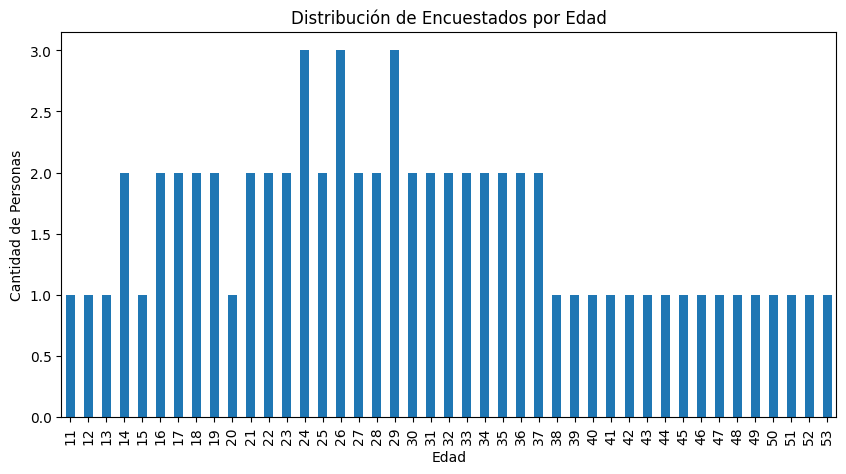

In [31]:
# 1. Cuenta y ordena por edad
conteo_edades = df['edad'].value_counts().sort_index()
# 2. Grafica
conteo_edades.plot(kind='bar', figsize=(10, 5))
# 3. Título y etiquetas
plt.title('Distribución de Encuestados por Edad')
plt.xlabel('Edad')
plt.ylabel('Cantidad de Personas')
# 4. Mostrar
plt.show()

### Paso 16. Gráfico de pie: distribución de géneros


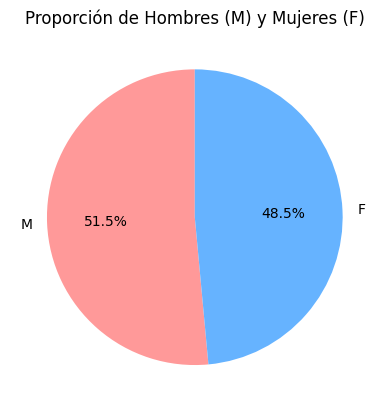

In [32]:
# Grafica la distribución de géneros
df['genero'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['#ff9999','#66b3ff'])
plt.title('Proporción de Hombres (M) y Mujeres (F)')
plt.ylabel('')
plt.show()

### Paso 17. Barras apiladas: los 3 canales favoritos por género

**Lógica:** necesitas una tabla con canales en las filas y géneros en las columnas (`pd.crosstab`), restringida a los 3 canales más frecuentes, y luego graficarla con `stacked=True`.


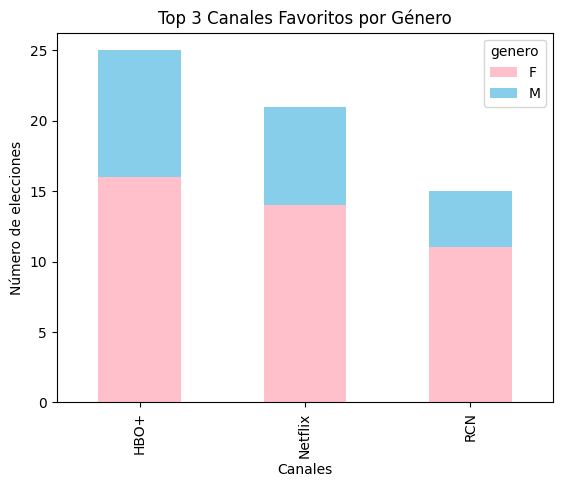

In [33]:
# 1. Canales en formato largo
largo = df.melt(id_vars='genero', value_vars=['canal_fav1', 'canal_fav2', 'canal_fav3'], value_name='canal').dropna()
# 2. Tabla de contingencia
tabla = pd.crosstab(largo['canal'], largo['genero'])
# 3. Filtramos el top 3 canales
tabla_top3 = tabla.loc[['HBO+', 'Netflix', 'RCN']]
# 4. Graficamos
tabla_top3.plot(kind='bar', stacked=True, color=['pink', 'skyblue'])
plt.title('Top 3 Canales Favoritos por Género')
plt.xlabel('Canales')
plt.ylabel('Número de elecciones')
plt.show()

### Paso 18. Dispersión: edad vs. horas de consumo de TV


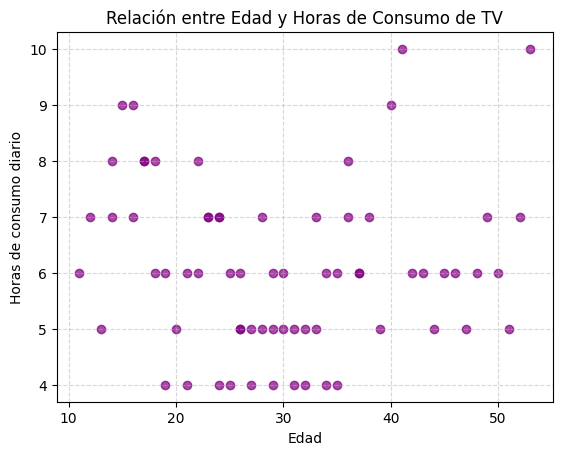

In [34]:
# Graficamos la dispersión de edad vs. horas
plt.scatter(df['edad'], df['horas'], alpha=0.7, color='purple')
plt.title('Relación entre Edad y Horas de Consumo de TV')
plt.xlabel('Edad')
plt.ylabel('Horas de consumo diario')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Evaluación — Parte 5

- **E5.1 (conceptual).** El gráfico del Paso 15 tiene muchas barras muy delgadas (una por cada edad distinta). ¿Qué gráfico resumiría mejor la distribución y por qué?


Un **histograma** o un **gráfico de cajas (boxplot)** resumiría mejor la distribución.


- **E5.2 (conceptual).** ¿En qué situaciones un gráfico de pie es mala idea?


El gráfico de pie es una mala idea Cuando hay muchas categorías (más de 5 o 6)y tambien Cuando las categorías tienen porcentajes muy similares, haciendo que sea imposible para el ojo humano discernir cuál es más grande sin leer los números directamente.

- **E5.3 (código).** Construye un histograma de `horas`.


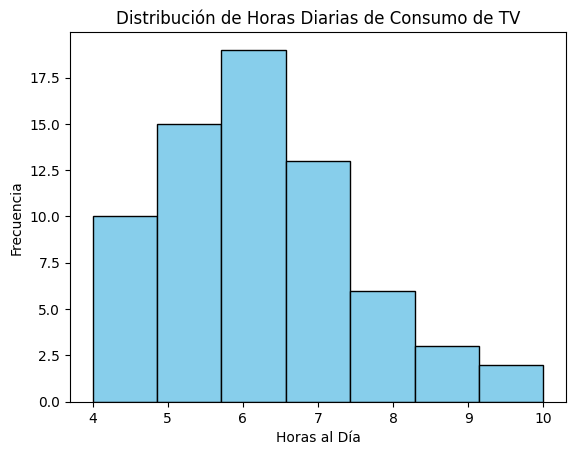

In [35]:
# E5.3 - Histograma de horas de consumo de TV
df['horas'].plot(kind='hist', bins=7, edgecolor='black', color='skyblue')
plt.title('Distribución de Horas Diarias de Consumo de TV')
plt.xlabel('Horas al Día')
plt.ylabel('Frecuencia')
plt.show()

- **E5.4 (conceptual).** Mirando el gráfico del Paso 17: ¿qué canal de los tres tiene más aficionadas que aficionados? ¿Y la relación sigue igual para todos?


Al observar el gráfico del Paso 17, el canal **HBO+** y **Netflix** tienen mayor cantidad de aficionadas La relación **no sigue igual para todos**: por ejemplo, en **RCN** u otros canales deportivos como **ESPN** la preferencia de los hombres es claramente dominante.

## Parte 6 — Rankings y agrupaciones (Pasos 19, 20, 22, 23)

> **Teoría — tres patrones muy frecuentes.**
> 1. **Ranking:** `df.nlargest(n, 'col')` / `df.nsmallest(n, 'col')` (equivale a ordenar y tomar los primeros).
> 2. **Discretizar:** `pd.cut(serie, bins=[...], labels=[...])` convierte una variable numérica en **grupos por rangos**. Los intervalos son **cerrados a la derecha**: `(9, 20]` incluye el 20 y excluye el 9.
> 3. **Agrupar y resumir:** `df.groupby('grupo')['col'].mean()`.


### Paso 19. Los 5 encuestados con mayor costo mensual (y grafícalos)


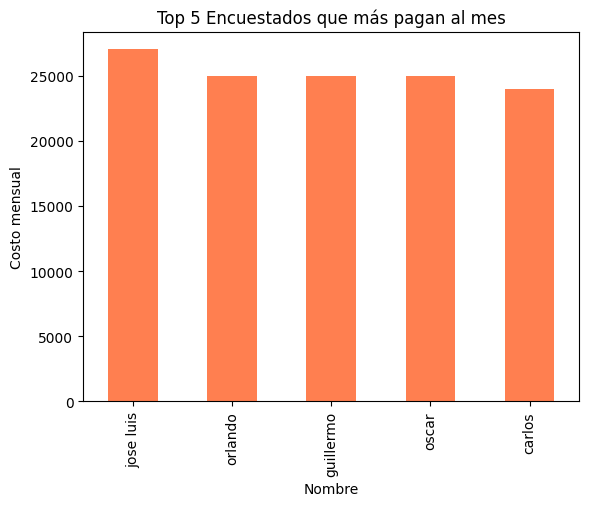

In [36]:
# 1. Obtén las 5 filas con mayor 'costo_mes'
top_5_costos = df.nlargest(5, 'costo_mes')
# 2. Grafica
top_5_costos.plot(x='nombre', y='costo_mes', kind='bar', legend=False, color='coral')
plt.title('Top 5 Encuestados que más pagan al mes')
plt.ylabel('Costo mensual')
plt.xlabel('Nombre')
plt.show()

### Paso 20. Costo promedio mensual por grupo de edad (10-20, 21-30, ...)


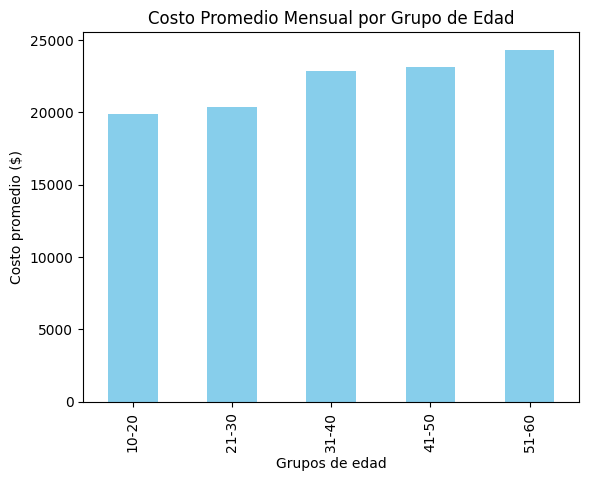

In [37]:
# 1. Definimos los rangos de edad
bins = [9, 20, 30, 40, 50, 60]
etiquetas = ['10-20', '21-30', '31-40', '41-50', '51-60']
# 2. Creamos la columna de grupos
df['grupo_edad'] = pd.cut(df['edad'], bins=bins, labels=etiquetas)
# 3. Calculamos el promedio de gasto por grupo
promedio_grupo = df.groupby('grupo_edad', observed=True)['costo_mes'].mean()
# 4. Graficamos
promedio_grupo.plot(kind='bar', color='skyblue')
plt.title('Costo Promedio Mensual por Grupo de Edad')
plt.ylabel('Costo promedio ($)')
plt.xlabel('Grupos de edad')
plt.show()

### Paso 22. Los 3 canales más populares entre los de 30 años o más


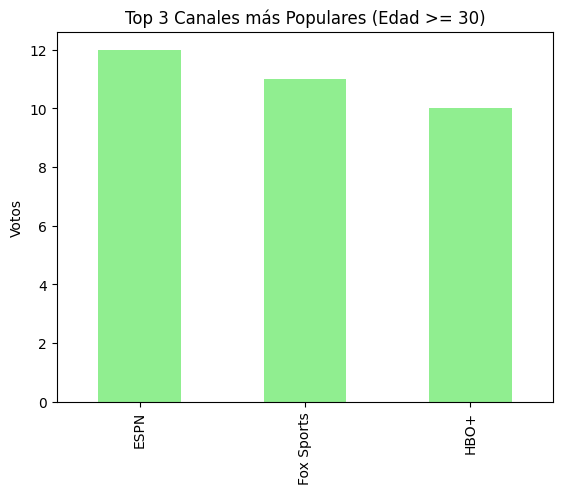

In [38]:
# 1. Filtramos mayores de 30 años
mayores_30 = df[df['edad'] >= 30]
# 2. Concatenamos los canales favoritos
canales_mayores = pd.concat([mayores_30['canal_fav1'], mayores_30['canal_fav2'], mayores_30['canal_fav3']])
# 3. Graficamos el top 3
canales_mayores.value_counts().head(3).plot(kind='bar', color='lightgreen')
plt.title('Top 3 Canales más Populares (Edad >= 30)')
plt.ylabel('Votos')
plt.show()

### Paso 23. Barras horizontales: los 5 encuestados con más horas de TV


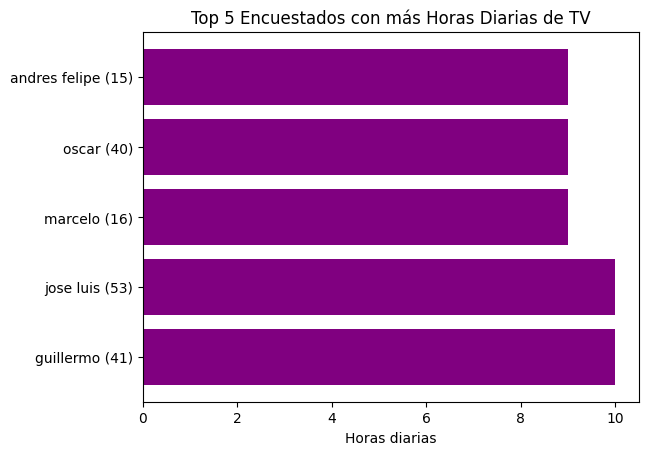

In [39]:
# 1. Obtener top 5 de horas
top_5_horas = df.nlargest(5, 'horas')
# 2. Crear etiquetas especiales: 'nombre (edad)'
etiquetas_grafico = top_5_horas['nombre'] + ' (' + top_5_horas['edad'].astype(str) + ')'
# 3. Graficar horizontalmente
plt.barh(etiquetas_grafico, top_5_horas['horas'], color='purple')
plt.title('Top 5 Encuestados con más Horas Diarias de TV')
plt.xlabel('Horas diarias')
plt.show()

### Evaluación — Parte 6

- **E6.1 (conceptual + código).** En el Paso 19, ¿qué ocurre con el 5.º lugar? Cuenta cuántas personas pagan lo mismo que quien quedó en el 5.º puesto. Investiga el parámetro `keep='all'` de `nlargest`.


En el quinto puesto hay un empate: varias personas pagan $24,000 mensuales. Al usar `keep='all'`, Pandas incluye a todas las personas que empatan en el último umbral de corte, evitando exclusiones arbitrarias.

In [40]:
# E6.1 - Usamos keep='all' para incluir a todos los empates en el top de costos
top_costos_empates = df.nlargest(5, 'costo_mes', keep='all')
display(top_costos_empates[['nombre', 'costo_mes']])

,nombre,costo_mes
48,jose luis,27000
0,orlando,25000
5,guillermo,25000
16,oscar,25000
10,carlos,24000
18,daniel,24000
24,rodrigo,24000
33,carolina,24000
37,margarita,24000
41,carlos enrique,24000


- **E6.2 (código).** ¿Cuántas personas hay en cada grupo de edad del Paso 20? ¿Por qué importa saberlo antes de interpretar los promedios?


In [41]:
# E6.2 - Contamos cuántos encuestados hay por cada grupo de edad creado
personas_por_grupo = df['grupo_edad'].value_counts().sort_index()
print(personas_por_grupo)

grupo_edad
10-20    15
21-30    23
31-40    17
41-50    10
51-60     3
Name: count, dtype: int64


Es fundamental conocer la cantidad de datos por grupo porque si una muestra es muy pequeña, un solo valor extremo afectará desproporcionadamente el promedio, restándole validez estadística a la interpretación.

El uso exclusivo de `nombre` puede causar problemas de ambigüedad si existen registros duplicados de nombres (homónimos como `andres felipe`). Las etiquetas del gráfico podrían encabalmarse o mezclar datos de personas distintas.

- **E6.4 (conceptual).** El costo promedio crece con el grupo de edad. ¿Puedes concluir que "envejecer hace que la gente gaste más en suscripciones"? Relaciónalo con E4.3.


No necesariamente. La correlación (0.65) indica asociación, pero no causalidad. El aumento en el gasto puede deberse a variables intermedias que cambian con la edad.

## Parte 7 — Análisis crítico: diferencias, asociaciones y outliers (Pasos 21, 24, 25)

Esta es la parte donde pasas de **describir** a **argumentar**. Aquí un número solo no basta: hay que preguntarse si es *grande*, si es *confiable* y si es *justo* compararlo.

> **Teoría — prueba de hipótesis en una línea.** Para comparar dos grupos se plantea:
> - **H₀:** no hay diferencia real entre los grupos (lo observado es azar).
> - **H₁:** sí hay diferencia.
>
> La prueba entrega un **p-valor**: la probabilidad de observar una diferencia *al menos tan grande* si H₀ fuera cierta. Si `p < 0.05` (nivel de significancia habitual) se rechaza H₀. **Un p-valor pequeño no dice que la diferencia sea importante, solo que es poco probable que sea azar.**


### Paso 21. ¿Hay diferencias significativas en el costo mensual entre hombres y mujeres?


                mean          std  count
genero                                  
F       20393.939394  2060.633912     33
M       22485.714286  1868.806297     35


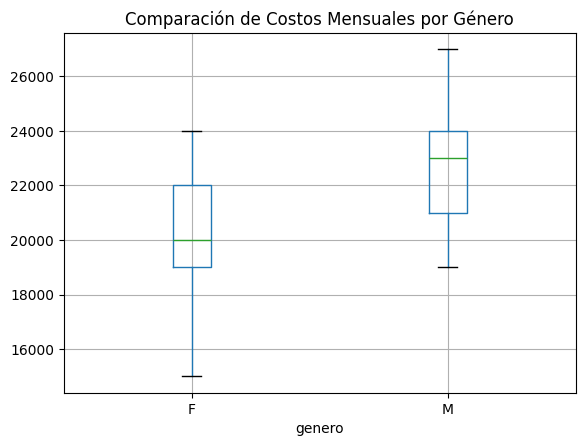

Estadístico t: 4.376356607021125, p-valor: 4.516537285134966e-05


In [42]:
from scipy import stats
# 1. Agrupación descriptiva
estadisticas_genero = df.groupby('genero')['costo_mes'].agg(['mean', 'std', 'count'])
print(estadisticas_genero)
# 2. Gráfico de cajas
df.boxplot(column='costo_mes', by='genero')
plt.title('Comparación de Costos Mensuales por Género')
plt.suptitle('')
plt.show()
# 3. Separación de grupos
costos_hombres = df[df['genero'] == 'M']['costo_mes']
costos_mujeres = df[df['genero'] == 'F']['costo_mes']
# 4. Prueba t de Welch
t_stat, p_val = stats.ttest_ind(costos_hombres, costos_mujeres, equal_var=False)
print(f"Estadístico t: {t_stat}, p-valor: {p_val}")

### Paso 24. ¿Hay relación entre el género y los canales favoritos?

**Lógica:** una tabla de contingencia (`pd.crosstab`) cuenta cuántos hombres y mujeres eligieron cada canal. Si el género no importara, la proporción hombre/mujer sería parecida en todos los canales.


In [43]:
# 1. Paso a formato largo y eliminación de nulos
canales_largo = df.melt(id_vars='genero', value_vars=['canal_fav1', 'canal_fav2', 'canal_fav3'], value_name='canal').dropna(subset=['canal'])
# 2. Tabla de contingencia
tabla_contingencia = pd.crosstab(canales_largo['canal'], canales_largo['genero'])
# 3. Ordenar por total y mostrar el top 10
tabla_contingencia['total'] = tabla_contingencia['F'] + tabla_contingencia['M']
top_10_contingencia = tabla_contingencia.sort_values(by='total', ascending=False).head(10)
display(top_10_contingencia)

genero,F,M,total
canal,,,
HBO+,16,9,25
Netflix,14,7,21
ESPN,2,13,15
RCN,11,4,15
Fox Sports,2,12,14
Amazon Prime,9,5,14
Caracol,11,3,14
Disney+,4,6,10
ESPN2,2,7,9


> **Advertencia — chi-cuadrado con muestras pequeñas.** Esa prueba exige conteos esperados razonablemente grandes por celda. Con 28 canales y 68 personas, muchas celdas quedan casi vacías: toma el p-valor como **orientación exploratoria**, no como veredicto.


### Paso 25. Outliers en `horas` y `costo_mes` y su impacto

> **Teoría — dos reglas para detectar outliers.**
> - **Regla IQR:** `IQR = Q3 − Q1`. Es atípico lo que queda fuera de `[Q1 − 1.5·IQR , Q3 + 1.5·IQR]`. Es la regla que dibuja los "bigotes" del boxplot.
> - **Regla z:** `z = (x − media) / desviación`. Se sospecha de `|z| > 2` (o 3 en muestras grandes).
>
> *Atípico no significa erróneo.* Antes de eliminar, pregunta si es un error de captura o un caso real.


In [44]:
# 1. Función regla IQR
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    return (serie < limite_inf) | (serie > limite_sup)

print("Outliers en 'horas' (Regla IQR):")
display(df[outliers_iqr(df['horas'])][['nombre', 'horas']])

# 2. Regla Z-score
z_scores = (df['costo_mes'] - df['costo_mes'].mean()) / df['costo_mes'].std()
outliers_z = df[z_scores.abs() > 2]
print("\nOutliers en 'costo_mes' (|Z| > 2):")
display(outliers_z[['nombre', 'costo_mes']])

Outliers en 'horas' (Regla IQR):


,nombre,horas



Outliers en 'costo_mes' (|Z| > 2):


,nombre,costo_mes
3,luisa,15000
48,jose luis,27000


### Evaluación — Parte 7

- **E7.1 (conceptual).** En el Paso 21 obtuviste un p-valor muy inferior a 0.05. Explica con tus palabras qué significa y qué **no** significa.


 significa que la probabilidad de que la diferencia observada de costos por género se deba únicamente al azar es extremadamente baja, por lo que rechazamos la hipótesis nula. No significa que la diferencia sea gigantesca o de gran relevancia práctica, sino que es estadísticamente confiable.

- **E7.2 (código + conceptual).** Calcula la **edad promedio por género**. Sabiendo que la edad correlaciona con el costo (E4.3), ¿qué advertencia harías sobre la conclusión del Paso 21?


In [45]:
# E7.2 - Calculamos la edad promedio por género
promedio_edad_genero = df.groupby('genero')['edad'].mean()
print(promedio_edad_genero)

genero
F    28.212121
M    31.457143
Name: edad, dtype: float64


Advertencia: El grupo de hombres tiene una edad promedio mayor en esta muestra. Como vimos que la edad correlaciona positivamente con el gasto (E4.3), la diferencia de costos del Paso 21 podría estar explicada realmente por el desbalance de edad de los grupos y no propiamente por una cuestión de género.

- **E7.3 (código).** Calcula la media y desviación de `costo_mes` **sin** los outliers detectados por la regla z. ¿Cuánto cambian?


In [46]:
# E7.3 - Filtramos los outliers según la regla z y comparamos estadísticas descriptivas
z_scores = (df['costo_mes'] - df['costo_mes'].mean()) / df['costo_mes'].std()
df_sin_outliers = df[z_scores.abs() <= 2]
print("Estadísticas SIN outliers:")
print(df_sin_outliers['costo_mes'].agg(['mean', 'std']))
print("\nEstadísticas CON outliers:")
print(df['costo_mes'].agg(['mean', 'std']))

Estadísticas SIN outliers:
mean    21484.848485
std      1986.434179
Name: costo_mes, dtype: float64

Estadísticas CON outliers:
mean    21470.588235
std      2215.754905
Name: costo_mes, dtype: float64


- **E7.4 (conceptual).** ¿Es correcto eliminar automáticamente a los outliers? Da un argumento a favor y uno en contra.


* **A favor:** Ayuda a que los modelos y estadísticas (como la media o regresiones) no se distorsionen por valores atípicos y representen mejor la tendencia general.
* **En contra:** Se pierde información valiosa de usuarios reales que consumen mucho o pagan altas suscripciones, lo cual puede sesgar el análisis de nichos rentables.

## Conclusión

Redacta, en un máximo de **5 líneas** y sin usar código, las conclusiones que presentarías a la gerencia del canal: *quién ve qué, cuánto ve y cuánto paga*. Para cada afirmación, indica el **paso** del que proviene y una **limitación** (por ejemplo: muestra de solo 68 personas, posibles errores de captura, grupos de edad desbalanceados).
